# IA en las empresas españolas: dónde están las oportunidades de negocio

**Yeswelab · laboratorio** · Datos del INE: *Encuesta sobre el uso de TIC y del comercio electrónico en las empresas 2025-2026* (uso de IA en el primer trimestre de 2026) y la edición anterior (primer trimestre de 2025), más el Directorio Central de Empresas (DIRCE) a 1 de enero de 2025.

La pregunta no es «¿cuántas empresas usan IA?», sino **qué productos y servicios de IA se les pueden ofrecer, a cuántas y por qué no los tienen ya**. Para alguien que monta automatizaciones, agentes y pilotos de IA para empresas.

Tablas usadas (todas públicas, API JSON de INEbase):

| Tabla | Contenido |
| --- | --- |
| [82382](https://www.ine.es/jaxi/Tabla.htm?tpx=82382&L=0) | IA en empresas de 10 o más empleados por actividad y tamaño, 2026 |
| [82394](https://www.ine.es/jaxi/Tabla.htm?tpx=82394&L=0) | IA en empresas de menos de 10 empleados, 2026 |
| [82404](https://www.ine.es/jaxi/Tabla.htm?tpx=82404&L=0) | IA por comunidades autónomas (10 o más empleados), 2026 |
| [82415](https://www.ine.es/jaxi/Tabla.htm?tpx=82415&L=0) | Error estándar de una variable de IA por estratos, 2026 |
| [76387](https://www.ine.es/jaxi/Tabla.htm?tpx=76387&L=0) / [76397](https://www.ine.es/jaxi/Tabla.htm?tpx=76397&L=0) | Lo mismo en la edición anterior (2025) |
| [39372](https://www.ine.es/jaxiT3/Tabla.htm?t=39372) | DIRCE: empresas por actividad (CNAE-2009) y asalariados, 1/1/2025 |

**Cómo leer los porcentajes** (notas del INE):
- **Uso de IA (D.1) y «la han considerado» (D.6):** sobre todas las empresas con conexión a internet.
- **Tecnologías (D.1.A–H), usos (D.2), cómo la consiguen (D.3) y datos personales (D.5):** sobre las empresas que **ya usan** IA.
- **Motivos para no usarla (D.7):** sobre las empresas que **la han considerado** y no la usan.

In [1]:
import json, os
import pandas as pd
import matplotlib.pyplot as plt
import ine
R = ine.redondear  # redondeo único, al final

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
DATOS, CACHE, RES = "datos", "cache", "resultados"
os.makedirs(os.path.join(RES, "graficos"), exist_ok=True)
TAMANOS = ["Total", "De 10 a 49", "De 50 a 249", "De 250 y más"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def tabla_tic(n):
    # Encuesta TIC por actividad y tamaño: columnas actividad, variable, tamaño, valor, código
    t = ine.ordenar(ine.descargar(n, DATOS))
    t = t.rename(columns=lambda k: "actividad" if k.startswith("Agrupación") else "variable" if k == "Principales variables" else "tamano" if k.startswith("Tamaño") else k)
    t["cod"] = t["variable"].map(ine.codigo)
    t["sec"] = t["actividad"].str.extract(r"^([\d.]+?)\.?\s")[0].fillna("T")
    return t

e26, e25 = tabla_tic(82382), tabla_tic(76387)
micro26 = ine.ordenar(ine.descargar(82394, DATOS)); micro26["cod"] = micro26["Principales variables"].map(ine.codigo)
micro25 = ine.ordenar(ine.descargar(76397, DATOS)); micro25["cod"] = micro25["Principales variables"].map(ine.codigo)
etiquetas = dict(zip(e26["cod"], e26["variable"].map(ine.etiqueta)))
print(len(e26), "series de 2026 ·", len(e25), "de 2025 ·", e26["actividad"].nunique(), "agrupaciones de actividad")

2356 series de 2026 · 2040 de 2025 · 19 agrupaciones de actividad


## 1. Panorama: la IA ha crecido en un año

Las preguntas son las mismas en las dos ediciones, aunque cambian de código: en 2025 son E.1 a E.5, y en 2026, D.1 a D.7. Se emparejan por su texto.

In [2]:
# Equivalencias 2025 → 2026 para las variables comparables (mismo enunciado)
EQUIV = {"E.1": "D.1", **{f"E.1.{l}": f"D.1.{l}" for l in "ABCDEFGH"}, **{f"E.2.{l}": f"D.2.{l}" for l in "ABCDEFG"},
         "E.4": "D.6", **{f"E.5.{l}": f"D.7.{l}" for l in "ABCDEFGH"}}

def total_por_tamano(t, anyo):
    p = t[t["actividad"] == "Total Empresas"].pivot_table(index="cod", columns="tamano", values="valor")[TAMANOS]
    if anyo == 2025:
        p = p.rename(index=EQUIV)
    return p

t26, t25 = total_por_tamano(e26, 2026), total_por_tamano(e25, 2025)
t26["Menos de 10"] = micro26.set_index("cod")["valor"]
t25["Menos de 10"] = micro25.set_index("cod").rename(index=EQUIV)["valor"]

panorama = pd.DataFrame({"2025": t25.loc["D.1"], "2026": t26.loc["D.1"]})
panorama["cambio_puntos"] = panorama["2026"] - panorama["2025"]
panorama["crecimiento_pct"] = 100 * panorama["cambio_puntos"] / panorama["2025"]
R(panorama).to_csv(f"{RES}/panorama_uso_ia.csv")
R(panorama)

,2025,2026,cambio_puntos,crecimiento_pct
tamano,,,,
Total,21.1,33.6,12.5,58.9
De 10 a 49,17.9,29.1,11.3,62.9
De 50 a 249,30.8,48.9,18.2,59.1
De 250 y más,58.2,74.4,16.2,27.7
Menos de 10,13.4,21.4,8.0,59.5


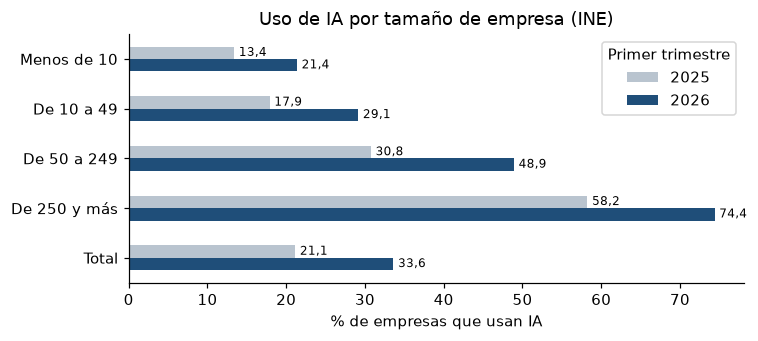

In [3]:
ax = panorama[["2025", "2026"]].loc[["Menos de 10", "De 10 a 49", "De 50 a 249", "De 250 y más", "Total"]].plot.barh(color=["#b9c4cf", "#1f4e79"], figsize=(7, 3.2))
ax.set_xlabel("% de empresas que usan IA"); ax.set_ylabel(""); ax.invert_yaxis(); ax.legend(title="Primer trimestre")
for p in ax.patches:
    ax.annotate(f"{p.get_width():.1f}".replace(".", ","), (p.get_width() + 0.6, p.get_y() + p.get_height() / 2), va="center", fontsize=8)
plt.title("Uso de IA por tamaño de empresa (INE)"); plt.tight_layout(); plt.savefig(f"{RES}/graficos/uso_ia_por_tamano.png"); plt.show()

## 2. El mercado en número de empresas

Porcentajes del INE × número de empresas del DIRCE. Solo se cuentan las divisiones CNAE que cubre la encuesta (10 a 82, sin finanzas ni comercio de vehículos), agrupadas en los mismos tramos de asalariados.

Es un orden de magnitud, no un censo. El DIRCE usa la CNAE-2009 y la encuesta, la CNAE-25. Además, la encuesta solo cuenta las empresas con internet, que en las de 10 o más empleados son casi todas.

In [4]:
dirce = ine.ordenar(ine.descargar(39372, CACHE, extra="&nult=1"))
dirce = dirce[dirce["Totales Territoriales"].notna()].copy()
dirce["div"] = dirce["nombre_serie"].str.extract(r"\.\s(\d{2,3})\s")[0]
TRAMO = {"De 10 a 19": "De 10 a 49", "De 20 a 49": "De 10 a 49", "De 50 a 99": "De 50 a 249", "De 100 a 199": "De 50 a 249",
         "De 200 a 249": "De 50 a 249", "De 250 a 999": "De 250 y más", "De 1000 a 4999": "De 250 y más",
         "De 5000 o más asalariados": "De 250 y más"}
dirce["tamano"] = dirce["Estrato de asalariados"].map(TRAMO)

# Agrupaciones de la encuesta → divisiones CNAE (y el grupo 951)
r = lambda a, b: [f"{i:02d}" for i in range(a, b + 1)]
SECTORES = {"1.1": r(10, 18), "1.2": r(19, 23), "1.3": r(24, 25), "1.4": r(26, 33), "1.5": r(35, 39), "2": r(41, 43),
            "3.1": ["46"], "3.2": ["47"], "3.3": r(49, 53), "3.4": r(55, 56), "3.5": r(58, 60), "3.6": r(61, 63) + ["951"],
            "3.7": ["68"], "3.8": r(69, 75), "3.9": r(77, 82)}
filas = []
for sec, divs in SECTORES.items():
    sel = dirce[dirce["div"].isin(divs) & dirce["tamano"].notna()]
    for tam, n in sel.groupby("tamano")["valor"].sum().items():
        filas.append({"sec": sec, "tamano": tam, "empresas": n})
n_emp = pd.DataFrame(filas).pivot_table(index="sec", columns="tamano", values="empresas", aggfunc="sum")[TAMANOS[1:]]
n_emp["Total"] = n_emp.sum(axis=1)
n_emp.loc["T"] = n_emp.sum()
n_emp.astype(int).to_csv(f"{RES}/empresas_dirce_por_sector.csv")
print("Empresas de 10 o más asalariados en los sectores de la encuesta:", f"{int(n_emp.loc['T', 'Total']):,}".replace(",", "."))
n_emp.astype(int)

Empresas de 10 o más asalariados en los sectores de la encuesta: 123.717


tamano,De 10 a 49,De 50 a 249,De 250 y más,Total
sec,,,,
1.1,9512,1364,69,10945
1.2,3123,886,39,4048
1.3,4937,595,13,5545
1.4,5933,1115,65,7113
1.5,1261,313,27,1601
2,19528,1525,32,21085
3.1,10690,1911,59,12660
3.2,6298,638,100,7036
3.3,7502,1130,85,8717


In [5]:
# Usuarias, demanda en espera (la han considerado y no la usan) y quienes nunca se lo han planteado
mercado = pd.DataFrame({"empresas": n_emp.loc["T", TAMANOS]})
mercado["usan_ia_pct"] = t26.loc["D.1", TAMANOS]
mercado["consideran_pct"] = t26.loc["D.6", TAMANOS]
mercado["nunca_pct"] = 100 - mercado["usan_ia_pct"] - mercado["consideran_pct"]
for k in ("usan_ia", "consideran", "nunca"):
    mercado[k] = mercado["empresas"] * mercado[f"{k}_pct"] / 100
# Compran a un proveedor externo (D.3.B, sobre las que usan IA)
mercado["con_proveedor_externo"] = mercado["usan_ia"] * t26.loc["D.3.B", TAMANOS] / 100
# La fila Total suma los tres tamaños (cada tamaño con su propio porcentaje)
CUENTAS = ["empresas", "usan_ia", "consideran", "nunca", "con_proveedor_externo"]
mercado.loc["Total", CUENTAS] = mercado.loc[TAMANOS[1:], CUENTAS].sum()
mercado_r = R(mercado)
for k in CUENTAS:
    mercado_r[k] = mercado[k].round(-2).astype(int)
mercado_r.to_csv(f"{RES}/mercado_empresas.csv")
mercado_r

,empresas,usan_ia_pct,consideran_pct,nunca_pct,usan_ia,consideran,nunca,con_proveedor_externo
tamano,,,,,,,,
Total,123700,33.6,8.8,57.6,39400,10800,73600,16300
De 10 a 49,108200,29.1,8.4,62.5,31500,9100,67600,12200
De 50 a 249,14700,48.9,11.5,39.6,7200,1700,5800,3600
De 250 y más,900,74.4,7.6,18.1,700,100,200,500


## 3. Qué compran las que ya usan IA, y qué crece

Los porcentajes de tecnologías y usos se calculan sobre las empresas que ya usan IA, que en 2026 son muchas más. Para medir el mercado real se multiplican por la tasa de uso. Así se obtiene el **porcentaje sobre todas las empresas**, y es esa cifra la que se compara entre años.

In [6]:
def sobre_total(t, cod):
    return t.loc[cod, "Total"] * t.loc["D.1", "Total"] / 100

cods = [f"D.1.{l}" for l in "ABCDEFGH"] + [f"D.2.{l}" for l in "ABCDEFG"]
tec = pd.DataFrame({
    "tipo": ["tecnología" if k.startswith("D.1") else "uso" for k in cods],
    "que": [etiquetas[k] for k in cods],
    "pct_usuarias_2025": [t25.loc[k, "Total"] for k in cods],
    "pct_usuarias_2026": [t26.loc[k, "Total"] for k in cods],
    "pct_empresas_2025": [sobre_total(t25, k) for k in cods],
    "pct_empresas_2026": [sobre_total(t26, k) for k in cods],
}, index=cods)
tec["cambio_puntos"] = tec["pct_empresas_2026"] - tec["pct_empresas_2025"]
tec["multiplica"] = tec["pct_empresas_2026"] / tec["pct_empresas_2025"]
tec["empresas_2026"] = (tec["pct_empresas_2026"] / 100 * n_emp.loc["T", "Total"]).round(-2).astype(int)
tec = tec.sort_values("cambio_puntos", ascending=False)
tec_r = R(tec); tec_r["multiplica"] = R(tec["multiplica"], 2); tec_r["empresas_2026"] = tec["empresas_2026"]
tec_r.to_csv(f"{RES}/tecnologias_y_usos.csv")
tec_r

,tipo,que,pct_usuarias_2025,pct_usuarias_2026,pct_empresas_2025,pct_empresas_2026,cambio_puntos,multiplica,empresas_2026
D.1.D,tecnología,"que genera imágenes, vídeos, sonidos o audio",53.9,62.7,11.4,21.1,9.7,1.85,26100
D.1.A,tecnología,de análisis del lenguaje escrito,49.6,57.3,10.5,19.2,8.8,1.84,23800
D.2.C,uso,organización de procesos de administración o gestión empresarial,29.8,42.4,6.3,14.2,7.9,2.26,17600
D.1.C,tecnología,"que genera lenguaje escrito o hablado, o códigos de programación",43.8,49.0,9.3,16.5,7.2,1.78,20400
D.2.A,uso,marketing o ventas,29.6,35.5,6.3,11.9,5.7,1.91,14800
D.1.B,tecnología,que convierte el lenguaje hablado en formato legible por una máquina,36.0,37.8,7.6,12.7,5.1,1.67,15700
D.2.F,uso,"gestión contable, de control o financiera",20.5,26.7,4.3,9.0,4.6,2.07,11100
D.1.G,tecnología,de automatización de flujos de trabajo o ayuda en la toma de decis...,33.4,34.2,7.1,11.5,4.4,1.63,14200
D.2.B,uso,procesos de producción o servicios,22.4,24.1,4.7,8.1,3.4,1.71,10000
D.2.G,uso,actividades de I+D o innovación,22.3,23.1,4.7,7.8,3.1,1.65,9600


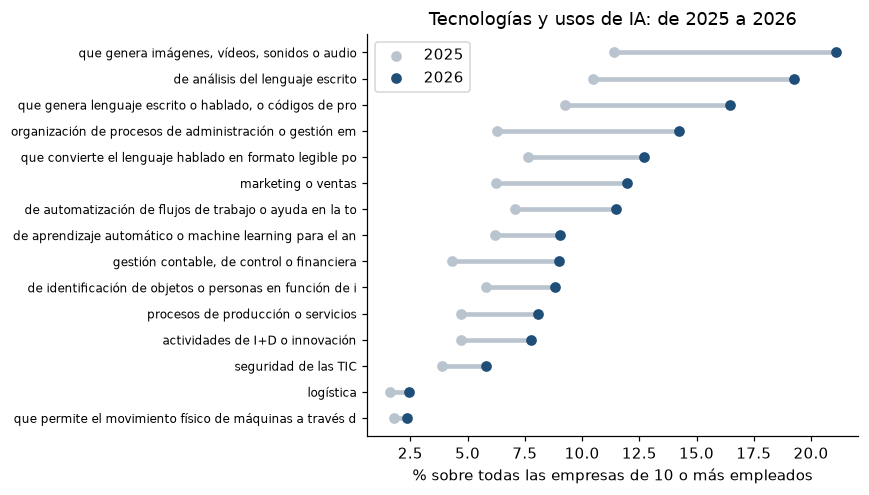

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.6))
d = tec.sort_values("pct_empresas_2026")
y = range(len(d))
ax.hlines(y, d["pct_empresas_2025"], d["pct_empresas_2026"], color="#b9c4cf", lw=3)
ax.scatter(d["pct_empresas_2025"], y, color="#b9c4cf", label="2025", zorder=3)
ax.scatter(d["pct_empresas_2026"], y, color="#1f4e79", label="2026", zorder=3)
ax.set_yticks(list(y)); ax.set_yticklabels([s[:55] for s in d["que"]], fontsize=8)
ax.set_xlabel("% sobre todas las empresas de 10 o más empleados"); ax.legend()
plt.title("Tecnologías y usos de IA: de 2025 a 2026"); plt.tight_layout(); plt.savefig(f"{RES}/graficos/tecnologias_y_usos.png"); plt.show()

In [8]:
# Cómo consiguen la IA las que la usan (2026; la pregunta cambió respecto a 2025, no se compara)
origen = t26.loc[["D.3.A", "D.3.B", "D.3.C", "D.3.D", "D.4", "D.5"], ["Total", "De 10 a 49", "De 50 a 249", "De 250 y más", "Menos de 10"]].copy()
origen.insert(0, "que", [etiquetas[k] for k in origen.index])
R(origen).to_csv(f"{RES}/origen_de_la_ia.csv")
R(origen)

tamano,que,Total,De 10 a 49,De 50 a 249,De 250 y más,Menos de 10
cod,,,,,,
D.3.A,% de empresas que adquieren software o sistemas de IA que son desa...,19.8,15.3,27.9,39.1,9.4
D.3.B,% de empresas que adquieren software o sistemas de IA que son desa...,43.3,38.7,50.2,66.5,27.6
D.3.C,% de empresas que adquirieron software o sistemas de IA de código ...,30.5,29.5,32.0,35.6,30.3
D.3.D,% de empresas que adquirieron software o sistemas de IA de código ...,75.2,73.1,78.4,86.5,73.4
D.4,% de empresas cuyo software de IA (de código abierto o cerrado) ha...,17.8,14.2,23.3,34.8,5.9
D.5,% de empresas que procesan datos sobre individuos utilizando Intel...,5.9,5.3,6.5,10.4,2.3


## 4. Por qué no la usan: cada freno es un servicio

Son las empresas que **la han considerado y no la usan**, es decir, las que ya tienen la necesidad. Cada motivo apunta a algo que se puede ofrecer. El número de empresas es el porcentaje × la demanda en espera de cada tamaño.

In [9]:
SERVICIO = {
    "D.7.B": "Formación práctica e implantación acompañada (hacerlo con ellos, no solo explicarlo)",
    "D.7.F": "Diagnóstico legal: RGPD y Reglamento europeo de IA, con política de uso interna",
    "D.7.E": "IA privada: modelos en local o en nube europea, sin que los datos salgan de la empresa",
    "D.7.D": "Auditoría y preparación de datos antes de automatizar",
    "D.7.A": "Pilotos de precio cerrado y retorno medido, con herramientas de código abierto",
    "D.7.C": "Integraciones con su ERP, CRM o correo (n8n, API) en vez de cambiar de sistema",
    "D.7.G": "Gobierno de la IA: criterios, supervisión humana y registro de decisiones",
    "D.7.H": "Experimento con sus datos para demostrar (o descartar) la utilidad antes de invertir",
}
frenos = pd.DataFrame({"freno": [etiquetas[k] for k in SERVICIO], "servicio": list(SERVICIO.values())}, index=list(SERVICIO))
for tam in ["Total", "De 10 a 49", "De 50 a 249", "Menos de 10"]:
    frenos[f"pct_{tam}"] = t26.loc[list(SERVICIO), tam]
frenos["pct_2025"] = t25.loc[list(SERVICIO), "Total"]
frenos["empresas_10_o_mas"] = sum(mercado.loc[tam, "consideran"] * t26.loc[list(SERVICIO), tam] / 100 for tam in TAMANOS[1:])
frenos = frenos.sort_values("pct_Total", ascending=False)
frenos_r = R(frenos); frenos_r["empresas_10_o_mas"] = frenos["empresas_10_o_mas"].round(-2).astype(int)
frenos_r.to_csv(f"{RES}/frenos_y_servicios.csv")
frenos_r

,freno,servicio,pct_Total,pct_De 10 a 49,pct_De 50 a 249,pct_Menos de 10,pct_2025,empresas_10_o_mas
D.7.B,que faltan conocimientos especializados relevantes en la empresa,"Formación práctica e implantación acompañada (hacerlo con ellos, n...",79.6,79.4,80.9,77.0,81.3,8600
D.7.F,falta de claridad sobre las consecuencias legales,"Diagnóstico legal: RGPD y Reglamento europeo de IA, con política d...",53.9,54.9,50.3,53.2,52.9,5900
D.7.E,preocupaciones con respecto a la violación de la protección de dat...,"IA privada: modelos en local o en nube europea, sin que los datos ...",52.2,51.5,54.3,53.4,53.6,5600
D.7.D,dificultades con la disponibilidad o calidad de los datos necesarios,Auditoría y preparación de datos antes de automatizar,47.1,46.5,49.1,45.4,47.9,5100
D.7.A,que los costes parecen demasiado altos,"Pilotos de precio cerrado y retorno medido, con herramientas de có...",46.9,45.8,50.7,61.3,48.3,5000
D.7.C,"incompatibilidad con equipos, software o sistemas existentes","Integraciones con su ERP, CRM o correo (n8n, API) en vez de cambia...",35.7,35.3,36.9,29.6,34.1,3800
D.7.G,consideraciones éticas,"Gobierno de la IA: criterios, supervisión humana y registro de dec...",28.0,27.8,29.4,26.1,24.1,3000
D.7.H,que las tecnologías de IA no son útiles para la empresa,Experimento con sus datos para demostrar (o descartar) la utilidad...,13.2,14.2,9.3,14.4,14.2,1400


## 5. Sectores: dónde hay demanda en espera y dónde se compra fuera

Para cada agrupación de actividad (empresas de 10 o más empleados):
- **Demanda en espera:** las que la han considerado y no la usan.
- **Compran a proveedor:** las que usan IA desarrollada por un proveedor externo.
- **Brecha de tamaño:** puntos de diferencia en el uso de IA entre las empresas de 50 a 249 empleados y las de 10 a 49 del mismo sector. Es lo que las grandes ya hacen y las pequeñas aún no.

In [10]:
NOMBRE = {"1.1": "Alimentación, textil, madera, papel y artes gráficas", "1.2": "Química, farmacia, plásticos y minerales",
          "1.3": "Metalurgia y productos metálicos", "1.4": "Electrónica, maquinaria, vehículos y muebles",
          "1.5": "Energía, agua y residuos", "2": "Construcción", "3.1": "Comercio al por mayor", "3.2": "Comercio al por menor",
          "3.3": "Transporte y almacenamiento", "3.4": "Hostelería", "3.5": "Edición, audiovisual y radiodifusión",
          "3.6": "Telecomunicaciones e informática", "3.7": "Inmobiliarias", "3.8": "Profesionales, científicas y técnicas",
          "3.9": "Administrativas y servicios auxiliares"}
ps = e26.pivot_table(index=["sec", "tamano"], columns="cod", values="valor")
filas = []
for sec, nombre in NOMBRE.items():
    tot = ps.loc[(sec, "Total")]
    n = n_emp.loc[sec]
    consideran = sum(n[t] * ps.loc[(sec, t), "D.6"] / 100 for t in TAMANOS[1:])
    usan = sum(n[t] * ps.loc[(sec, t), "D.1"] / 100 for t in TAMANOS[1:])
    filas.append({"sec": sec, "sector": nombre, "empresas": n["Total"], "usan_ia_pct": tot["D.1"], "consideran_pct": tot["D.6"],
                  "demanda_en_espera": consideran, "usan_ia": usan, "con_proveedor_externo": usan * tot["D.3.B"] / 100,
                  "falta_conocimiento_pct": tot["D.7.B"], "costes_pct": tot["D.7.A"],
                  "automatizacion_flujos_pct": tot["D.1.G"], "gestion_empresarial_pct": tot["D.2.C"],
                  "brecha_50_249_vs_10_49": ps.loc[(sec, "De 50 a 249"), "D.1"] - ps.loc[(sec, "De 10 a 49"), "D.1"]})
sectores = pd.DataFrame(filas).set_index("sec").sort_values("demanda_en_espera", ascending=False)
sectores_r = R(sectores)
for k in ("empresas", "demanda_en_espera", "usan_ia", "con_proveedor_externo"):
    sectores_r[k] = sectores[k].round(-2).astype(int)
sectores_r.to_csv(f"{RES}/sectores.csv")
sectores_r

,sector,empresas,usan_ia_pct,consideran_pct,demanda_en_espera,usan_ia,con_proveedor_externo,falta_conocimiento_pct,costes_pct,automatizacion_flujos_pct,gestion_empresarial_pct,brecha_50_249_vs_10_49
sec,,,,,,,,,,,,
3.1,Comercio al por mayor,12700,37.8,11.8,1500,4600,1900,76.8,44.4,30.3,37.6,9.5
2,Construcción,21100,22.6,6.3,1300,4600,1800,79.1,44.6,22.2,32.0,10.6
3.8,"Profesionales, científicas y técnicas",12200,58.7,9.9,1300,6900,3200,77.0,41.0,42.0,53.2,26.8
3.4,Hostelería,15000,23.9,7.5,1100,3300,1600,78.3,52.2,30.0,38.4,26.2
1.1,"Alimentación, textil, madera, papel y artes gráficas",10900,28.9,9.4,1000,3000,1300,86.7,47.2,25.6,39.4,14.6
3.9,Administrativas y servicios auxiliares,10600,30.0,8.5,900,2900,1200,76.6,38.2,31.2,41.1,16.9
1.4,"Electrónica, maquinaria, vehículos y muebles",7100,33.9,11.7,800,2200,1000,86.5,49.9,35.7,42.2,17.1
3.2,Comercio al por menor,7000,28.1,9.9,700,1900,700,83.4,56.3,28.6,36.7,25.0
3.3,Transporte y almacenamiento,8700,23.3,8.1,700,1900,800,81.4,49.4,27.0,37.8,18.9


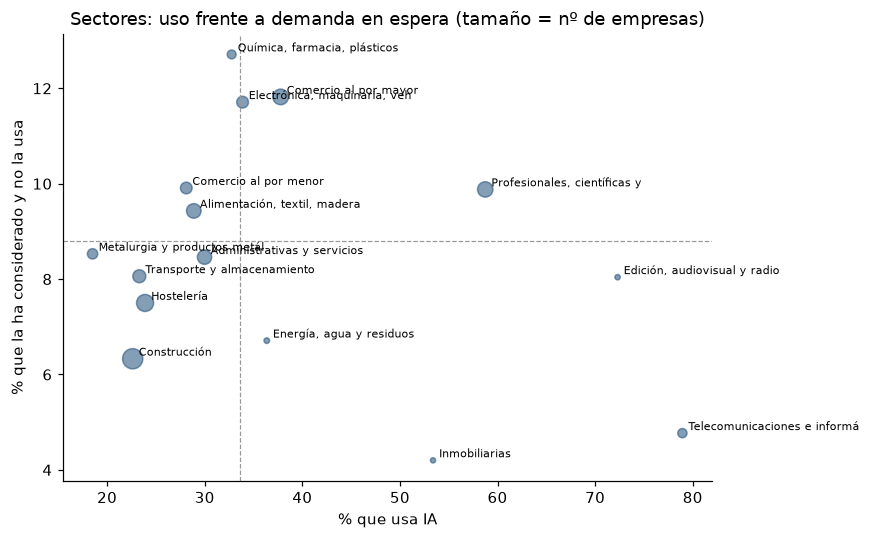

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sectores["usan_ia_pct"], sectores["consideran_pct"], s=sectores["empresas"] / 120, color="#1f4e79", alpha=.55)
for sec, f in sectores.iterrows():
    ax.annotate(f["sector"][:28], (f["usan_ia_pct"], f["consideran_pct"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.axvline(t26.loc["D.1", "Total"], color="#999", lw=.8, ls="--"); ax.axhline(t26.loc["D.6", "Total"], color="#999", lw=.8, ls="--")
ax.set_xlabel("% que usa IA"); ax.set_ylabel("% que la ha considerado y no la usa")
plt.title("Sectores: uso frente a demanda en espera (tamaño = nº de empresas)"); plt.tight_layout()
plt.savefig(f"{RES}/graficos/sectores_uso_vs_demanda.png"); plt.show()

In [12]:
# Crecimiento del uso por sector, solo donde la agrupación se define igual en las dos ediciones
MISMA_DEF = {"1.1": "1.1", "1.2": "1.2", "1.3": "1.3", "1.4": "1.4", "1.5": "1.5", "2": "2", "3.3": "3.2", "3.7": "3.5", "3.8": "3.6", "3.9": "3.7"}
p25 = e25[e25["tamano"] == "Total"].pivot_table(index="sec", columns="cod", values="valor")
crec = pd.DataFrame({"sector": [NOMBRE[s] for s in MISMA_DEF], "usan_ia_2025": [p25.loc[v, "E.1"] for v in MISMA_DEF.values()],
                     "usan_ia_2026": [ps.loc[(s, "Total"), "D.1"] for s in MISMA_DEF]}, index=list(MISMA_DEF))
crec["cambio_puntos"] = crec["usan_ia_2026"] - crec["usan_ia_2025"]
crec = crec.sort_values("cambio_puntos", ascending=False)
R(crec).to_csv(f"{RES}/crecimiento_por_sector.csv")
R(crec)

,sector,usan_ia_2025,usan_ia_2026,cambio_puntos
3.8,"Profesionales, científicas y técnicas",38.5,58.7,20.3
3.7,Inmobiliarias,34.8,53.4,18.6
1.5,"Energía, agua y residuos",22.4,36.4,14.0
1.1,"Alimentación, textil, madera, papel y artes gráficas",15.2,28.9,13.7
1.2,"Química, farmacia, plásticos y minerales",19.6,32.8,13.1
1.4,"Electrónica, maquinaria, vehículos y muebles",22.0,33.9,11.9
2,Construcción,11.4,22.6,11.2
3.9,Administrativas y servicios auxiliares,19.2,30.0,10.8
3.3,Transporte y almacenamiento,14.9,23.3,8.4
1.3,Metalurgia y productos metálicos,13.4,18.5,5.1


## 6. Comunidades autónomas (empresas de 10 o más empleados)

In [13]:
cc = ine.ordenar(ine.descargar(82404, DATOS))
cc = cc.rename(columns=lambda k: "ccaa" if k.startswith("Comunidades") else "variable" if k == "Principales variables" else "agr" if k.startswith("Agrupación") else k)
cc["cod"] = cc["variable"].map(ine.codigo)
ccaa = cc[cc["agr"] == "Total Empresas"].pivot_table(index="ccaa", columns="cod", values="valor")[["D.1", "D.6", "D.7.A", "D.7.B"]]
ccaa.columns = ["usan_ia_pct", "consideran_pct", "costes_pct", "falta_conocimiento_pct"]
ccaa = ccaa.sort_values("usan_ia_pct", ascending=False)
R(ccaa).to_csv(f"{RES}/comunidades.csv")
R(ccaa)

,usan_ia_pct,consideran_pct,costes_pct,falta_conocimiento_pct
ccaa,,,,
Cataluña,40.5,8.9,52.5,75.7
"Madrid, Comunidad de",40.1,9.3,45.9,74.8
"Navarra, Comunidad Foral de",36.5,6.8,47.2,75.2
Ceuta,35.7,6.0,29.4,100.0
Comunitat Valenciana,34.1,8.0,52.1,79.4
Total nacional,33.6,8.8,46.9,79.6
Andalucía,31.8,8.5,45.9,80.6
"Asturias, Principado de",30.7,8.9,44.5,87.4
Canarias,30.3,10.1,32.3,76.4


## 7. Cuánto fiarse: error estándar del INE

El INE publica el error estándar de una sola variable de IA (D.1.A, análisis del lenguaje escrito) por estratos. Sirve de referencia del tamaño de la incertidumbre en cada sector. Un intervalo del 95 % es ± 1,96 errores estándar: diferencias menores entre sectores no son concluyentes.

In [14]:
se = ine.ordenar(ine.descargar(82415, DATOS))
se = se.rename(columns=lambda k: "estrato" if k.startswith("Estrato") else k)[["estrato", "valor"]].rename(columns={"valor": "error_estandar"})
se["margen_95"] = 1.96 * se["error_estandar"]
R(se, 2).to_csv(f"{RES}/error_estandar_d1a.csv", index=False)
print("Margen al 95 %: de", R(se["margen_95"].min()), "a", R(se["margen_95"].max()), "puntos según el estrato")
R(se, 2)

Margen al 95 %: de 0.9 a 8.8 puntos según el estrato


,estrato,error_estandar,margen_95
0,Total España,0.45,0.88
1,De 10 a 49 remunerados,0.52,1.02
2,De 50 a 249 remunerados,0.98,1.92
3,De 250 y más remunerados,0.44,0.86
4,"1.1. Alimentación, bebidas tabaco, industria textil, confección de...",1.24,2.43
5,"1.2. Coquerias y refino de petróleo, industria química, fabricació...",1.64,3.21
6,1.3. Metalurgia y fabricación de productos metálicos ( CNAE 24-25),1.17,2.29
7,"1.4. Productos informáticos, electrónicos y ópticos, fabricación d...",1.50,2.94
8,"1.5. Energía, gas, vapor y agua (CNAE 35-39)",2.26,4.43
9,2. Total Construcción (CNAE 41-43),1.38,2.70


## 8. Oportunidades: qué ofrecer y a quién

Cada fila es un producto o servicio que se deduce de los datos, con la cifra que lo respalda. El orden va de lo más directo para un perfil que implanta automatizaciones, agentes y pilotos de IA a lo menos.

In [15]:
es = lambda v: str(v).replace(".", ",")  # coma decimal en los textos
ef = lambda cod: int(round(frenos.loc[cod, "empresas_10_o_mas"], -2))
op = [
    ("Implantación acompañada: piloto + formación del equipo", "Empresas que la han considerado y no saben cómo",
     f"{es(R(t26.loc['D.7.B', 'Total']))} % de las que la han considerado citan falta de conocimientos", ef("D.7.B")),
    ("Automatización del back office (documentos, correo, facturas) con IA", "Pymes que ya usan IA",
     f"Uso en administración y gestión: del {es(R(tec.loc['D.2.C', 'pct_empresas_2025']))} % al {es(R(tec.loc['D.2.C', 'pct_empresas_2026']))} % de las empresas (×{es(R(tec.loc['D.2.C', 'multiplica'], 2))})",
     int(tec.loc["D.2.C", "empresas_2026"])),
    ("Desarrollo a medida como proveedor externo", "Empresas que usan IA",
     f"{es(R(t26.loc['D.3.B', 'Total']))} % de las que usan IA la tienen desarrollada por un proveedor externo",
     int(round(mercado.loc["Total", "con_proveedor_externo"], -2))),
    ("Diagnóstico legal y de privacidad (RGPD, Reglamento europeo de IA)", "Empresas que la han considerado",
     f"{es(R(t26.loc['D.7.F', 'Total']))} % citan dudas legales y {es(R(t26.loc['D.7.E', 'Total']))} % la privacidad", ef("D.7.F")),
    ("IA privada: modelos locales o en nube europea", "Empresas con datos sensibles",
     f"{es(R(t26.loc['D.7.E', 'Total']))} % de las que la han considerado temen por la protección de datos", ef("D.7.E")),
    ("Preparación de datos antes de automatizar", "Empresas que la han considerado",
     f"{es(R(t26.loc['D.7.D', 'Total']))} % citan datos insuficientes o de mala calidad", ef("D.7.D")),
    ("Pilotos de precio cerrado para microempresas", "Empresas de menos de 10 empleados",
     f"{es(R(t26.loc['D.7.A', 'Menos de 10']))} % de las micro que la han considerado ven los costes demasiado altos (frente al {es(R(t26.loc['D.7.A', 'Total']))} % en las de 10 o más)", None),
    ("Integraciones con ERP, CRM y correo en vez de cambiar de sistema", "Empresas que la han considerado",
     f"{es(R(t26.loc['D.7.C', 'Total']))} % citan incompatibilidad con sus sistemas", ef("D.7.C")),
]
oportunidades = pd.DataFrame(op, columns=["producto_o_servicio", "para_quien", "dato", "empresas_10_o_mas"])
oportunidades["empresas_10_o_mas"] = oportunidades["empresas_10_o_mas"].astype("Int64")
oportunidades.index = range(1, len(oportunidades) + 1)
oportunidades.to_csv(f"{RES}/oportunidades.csv", index_label="orden")
oportunidades

,producto_o_servicio,para_quien,dato,empresas_10_o_mas
1,Implantación acompañada: piloto + formación del equipo,Empresas que la han considerado y no saben cómo,"79,6 % de las que la han considerado citan falta de conocimientos",8600
2,"Automatización del back office (documentos, correo, facturas) con IA",Pymes que ya usan IA,"Uso en administración y gestión: del 6,3 % al 14,2 % de las empres...",17600
3,Desarrollo a medida como proveedor externo,Empresas que usan IA,"43,3 % de las que usan IA la tienen desarrollada por un proveedor ...",16300
4,"Diagnóstico legal y de privacidad (RGPD, Reglamento europeo de IA)",Empresas que la han considerado,"53,9 % citan dudas legales y 52,2 % la privacidad",5900
5,IA privada: modelos locales o en nube europea,Empresas con datos sensibles,"52,2 % de las que la han considerado temen por la protección de datos",5600
6,Preparación de datos antes de automatizar,Empresas que la han considerado,"47,1 % citan datos insuficientes o de mala calidad",5100
7,Pilotos de precio cerrado para microempresas,Empresas de menos de 10 empleados,"61,3 % de las micro que la han considerado ven los costes demasiad...",<NA>
8,"Integraciones con ERP, CRM y correo en vez de cambiar de sistema",Empresas que la han considerado,"35,7 % citan incompatibilidad con sus sistemas",3800


## 9. Resumen para decidir

Cifras clave que usa el artículo, en un solo fichero.

In [16]:
k = lambda x, d=1: R(float(x), d)
resumen = {
    "fecha_datos": "Uso de IA en el primer trimestre de 2026 y de 2025 (INE, ETICCE); empresas: DIRCE a 1/1/2025",
    "uso_ia_10_o_mas_2025": k(panorama.loc["Total", "2025"]), "uso_ia_10_o_mas_2026": k(panorama.loc["Total", "2026"]),
    "uso_ia_cambio_puntos": k(panorama.loc["Total", "cambio_puntos"]), "uso_ia_crecimiento_pct": k(panorama.loc["Total", "crecimiento_pct"]),
    "uso_ia_10_49_2026": k(panorama.loc["De 10 a 49", "2026"]), "uso_ia_250_2026": k(panorama.loc["De 250 y más", "2026"]),
    "uso_ia_micro_2025": k(panorama.loc["Menos de 10", "2025"]), "uso_ia_micro_2026": k(panorama.loc["Menos de 10", "2026"]),
    "empresas_10_o_mas_sectores_encuesta": int(round(n_emp.loc["T", "Total"], -2)),
    "empresas_usan_ia_10_o_mas": int(round(mercado.loc["Total", "usan_ia"], -2)),
    "empresas_demanda_en_espera_10_o_mas": int(round(mercado.loc["Total", "consideran"], -2)),
    "empresas_nunca_10_o_mas": int(round(mercado.loc["Total", "nunca"], -2)),
    "empresas_con_proveedor_externo_10_o_mas": int(round(mercado.loc["Total", "con_proveedor_externo"], -2)),
    "consideran_pct_10_o_mas": k(t26.loc["D.6", "Total"]), "nunca_pct_10_o_mas": k(100 - t26.loc["D.1", "Total"] - t26.loc["D.6", "Total"]),
    "proveedor_externo_pct": k(t26.loc["D.3.B", "Total"]), "codigo_cerrado_pct": k(t26.loc["D.3.D", "Total"]),
    "codigo_abierto_pct": k(t26.loc["D.3.C", "Total"]), "desarrollo_propio_pct": k(t26.loc["D.3.A", "Total"]),
    "freno_principal": frenos.index[0], "freno_principal_pct": k(frenos["pct_Total"].iloc[0]),
    "freno_costes_micro_pct": k(t26.loc["D.7.A", "Menos de 10"]),
    "sector_mas_demanda_en_espera": sectores.index[0], "sector_mas_demanda_en_espera_empresas": int(round(sectores["demanda_en_espera"].iloc[0], -2)),
    "uso_que_mas_crece": tec.index[0], "uso_que_mas_crece_puntos": k(tec["cambio_puntos"].iloc[0]),
}
json.dump(resumen, open(f"{RES}/resumen.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
resumen

{'fecha_datos': 'Uso de IA en el primer trimestre de 2026 y de 2025 (INE, ETICCE); empresas: DIRCE a 1/1/2025',
 'uso_ia_10_o_mas_2025': 21.1,
 'uso_ia_10_o_mas_2026': 33.6,
 'uso_ia_cambio_puntos': 12.5,
 'uso_ia_crecimiento_pct': 58.9,
 'uso_ia_10_49_2026': 29.1,
 'uso_ia_250_2026': 74.4,
 'uso_ia_micro_2025': 13.4,
 'uso_ia_micro_2026': 21.4,
 'empresas_10_o_mas_sectores_encuesta': 123700,
 'empresas_usan_ia_10_o_mas': 39400,
 'empresas_demanda_en_espera_10_o_mas': 10800,
 'empresas_nunca_10_o_mas': 73600,
 'empresas_con_proveedor_externo_10_o_mas': 16300,
 'consideran_pct_10_o_mas': 8.8,
 'nunca_pct_10_o_mas': 57.6,
 'proveedor_externo_pct': 43.3,
 'codigo_cerrado_pct': 75.2,
 'codigo_abierto_pct': 30.5,
 'desarrollo_propio_pct': 19.8,
 'freno_principal': 'D.7.B',
 'freno_principal_pct': 79.6,
 'freno_costes_micro_pct': 61.3,
 'sector_mas_demanda_en_espera': '3.1',
 'sector_mas_demanda_en_espera_empresas': 1500,
 'uso_que_mas_crece': 'D.1.D',
 'uso_que_mas_crece_puntos': 9.7}